# 07 — Variáveis Aleatórias Discretas

Até aqui calculamos probabilidades de **eventos** ("sair par", "testar positivo"). Mas muitas perguntas são sobre **números**: quantas caras em 10 lançamentos? Quantos clientes chegam por hora? Quantas tentativas até o primeiro acerto?

Uma **variável aleatória** associa um número a cada resultado de um experimento. E a **distribuição de probabilidade** dela diz que chance cada número tem. É a versão **teórica** dos histogramas e das tabelas de frequência da Parte I.

Neste notebook vamos:
- Definir **variável aleatória** e **função de probabilidade (PMF)**
- Calcular o **valor esperado** e a **variância** de uma variável aleatória
- Conhecer as distribuições **Bernoulli**, **binomial**, **Poisson** e **geométrica**
- Usar o módulo `scipy.stats`, que traz todas elas prontas

## 1. Importando bibliotecas

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(42)

## 🎓 Conceito: variável aleatória e função de probabilidade

Uma **variável aleatória** (geralmente escrita com letra maiúscula, como $X$) é uma regra que transforma cada resultado de um experimento num número. Exemplo: jogamos dois dados e $X$ = a **soma** dos dois.

Ela é **discreta** quando assume valores "contáveis" (0, 1, 2, ...), como as variáveis discretas do notebook 01.

A **função de probabilidade** (PMF, de *probability mass function*) dá a chance de cada valor: $P(X = k)$. Ela obedece aos axiomas: cada valor fica entre 0 e 1, e **a soma de todos é 1**.

Analogia: a PMF é o **histograma de frequências relativas** que veríamos se repetíssemos o experimento infinitas vezes.

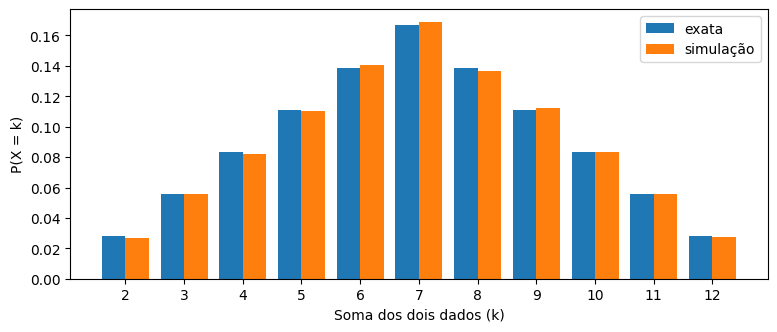

Soma das probabilidades: 1.0000
P(X = 7) exata = 0.1667 (6/36)   simulada = 0.1688


In [2]:
# PMF exata da soma de dois dados: contando as 36 combinações.
somas = [d1 + d2 for d1 in range(1, 7) for d2 in range(1, 7)]   # duas repetições "for" na mesma list comprehension
pmf_exata = pd.Series(somas).value_counts(normalize=True).sort_index()

# PMF estimada por simulação: 100.000 pares de dados.
simulado = rng.integers(1, 7, 100_000) + rng.integers(1, 7, 100_000)
pmf_simulada = pd.Series(simulado).value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(pmf_exata.index - 0.2, pmf_exata, width=0.4, label="exata")       # barras deslocadas para ficarem lado a lado
ax.bar(pmf_simulada.index + 0.2, pmf_simulada, width=0.4, label="simulação")
ax.set_xticks(range(2, 13))
ax.set_xlabel("Soma dos dois dados (k)")
ax.set_ylabel("P(X = k)")
ax.legend()
plt.show()

print(f"Soma das probabilidades: {pmf_exata.sum():.4f}")
print(f"P(X = 7) exata = {pmf_exata[7]:.4f} (6/36)   simulada = {pmf_simulada[7]:.4f}")

**Conclusão:** a PMF da soma de dois dados tem formato de **triângulo**: o 7 é o valor mais provável (**6/36 = 0,1667**), porque pode ser obtido de 6 formas, enquanto o 2 e o 12 só têm uma forma cada (1/36). As barras da simulação acompanham as exatas de perto (0,1688 para o 7), e a soma de todas as probabilidades é **1**, como manda o axioma.

Repare que um único dado tem distribuição **uniforme** (todos os valores com 1/6), mas a **soma** de dois já não é: os valores do meio ficam mais prováveis. Somar variáveis aleatórias "empurra" a distribuição para um formato de sino, uma pista do **Teorema Central do Limite** (notebook 10).

## 🎓 Conceito: valor esperado e variância

O **valor esperado** (ou esperança) $E[X]$ é a **média de longo prazo** da variável: a média que obteríamos repetindo o experimento infinitas vezes. É a média ponderada dos valores pelas suas probabilidades:

$$E[X] = \sum_k k \cdot P(X = k)$$

A **variância** mede o espalhamento em torno do valor esperado, da mesma forma que a variância da Parte I:

$$\text{Var}(X) = E\big[(X - E[X])^2\big] = \sum_k (k - E[X])^2 \cdot P(X = k)$$

E o desvio padrão é $\sqrt{\text{Var}(X)}$.

Duas propriedades muito úteis:
- **Linearidade da esperança:** $E[X + Y] = E[X] + E[Y]$ **sempre**, mesmo que $X$ e $Y$ sejam dependentes. E $E[aX + b] = a\,E[X] + b$.
- **Variância da soma:** $\text{Var}(X + Y) = \text{Var}(X) + \text{Var}(Y)$ quando $X$ e $Y$ são **independentes**. E $\text{Var}(aX + b) = a^2\,\text{Var}(X)$ (somar uma constante não muda o espalhamento).

In [3]:
# Um dado: valores 1 a 6, cada um com probabilidade 1/6.
valores = np.arange(1, 7)
probs = np.full(6, 1 / 6)                    # np.full cria um vetor com 6 cópias de 1/6
esperanca_dado = np.sum(valores * probs)
variancia_dado = np.sum((valores - esperanca_dado) ** 2 * probs)
print(f"Um dado:   E[X] = {esperanca_dado:.4f}   Var(X) = {variancia_dado:.4f}")

# Soma de dois dados, a partir da PMF exata.
k = pmf_exata.index.to_numpy()
esperanca_soma = np.sum(k * pmf_exata.values)
variancia_soma = np.sum((k - esperanca_soma) ** 2 * pmf_exata.values)
print(f"Dois dados (PMF):         E = {esperanca_soma:.4f}   Var = {variancia_soma:.4f}")
print(f"Dois dados (propriedades): E = {2 * esperanca_dado:.4f}   Var = {2 * variancia_dado:.4f}")
print(f"Dois dados (simulação):    E ≈ {simulado.mean():.4f}   Var ≈ {simulado.var():.4f}")

Um dado:   E[X] = 3.5000   Var(X) = 2.9167
Dois dados (PMF):         E = 7.0000   Var = 5.8333
Dois dados (propriedades): E = 7.0000   Var = 5.8333
Dois dados (simulação):    E ≈ 7.0055   Var ≈ 5.7999


**Conclusão:** um dado tem valor esperado **3,5**, um número que o dado nunca mostra! O valor esperado não é "o valor mais provável", e sim a **média de longo prazo**. A variância de um dado é **2,9167**.

Para dois dados, as três formas de calcular concordam: pela PMF, pelas propriedades (2 × 3,5 = **7** e, como os dados são independentes, 2 × 2,9167 = **5,8333**) e pela simulação (7,0055 e 5,7999). As propriedades poupam muito trabalho: para a soma de 100 dados, não precisaríamos montar nenhuma tabela.

## 🎓 Conceito: distribuição de Bernoulli

A variável aleatória mais simples: um experimento com **dois resultados**, "sucesso" (1) com probabilidade $p$ e "fracasso" (0) com probabilidade $1 - p$.
- Lançar uma moeda (cara = 1), um cliente comprar ou não, uma pessoa ter renda alta ou não.
- $E[X] = p$ e $\text{Var}(X) = p(1-p)$.

A variância é máxima quando $p = 0{,}5$ (máxima incerteza) e zero quando $p = 0$ ou $p = 1$ (certeza).

🔗 **Ponte para o ML:** o alvo de uma **classificação binária** (ML-02) é uma variável de Bernoulli. A regressão logística modela exatamente o $p$ dessa Bernoulli para cada pessoa.

## 🎓 Conceito: distribuição binomial

Repetimos $n$ vezes um experimento de Bernoulli **independente**, sempre com a mesma probabilidade $p$, e contamos os sucessos. O número de sucessos $X$ tem distribuição **binomial**, $X \sim \text{Binomial}(n, p)$:

$$P(X = k) = \binom{n}{k}\, p^k\, (1-p)^{n-k}$$

De onde vem a fórmula? Uma sequência específica com $k$ sucessos e $n-k$ fracassos tem probabilidade $p^k (1-p)^{n-k}$ (regra do produto para eventos independentes). E existem $\binom{n}{k}$ sequências assim (as combinações do notebook 05: escolher **em quais** das $n$ tentativas ocorrem os sucessos).

Como $X$ é a soma de $n$ Bernoullis independentes, as propriedades da esperança e da variância dão: $E[X] = np$ e $\text{Var}(X) = np(1-p)$.

Exemplo: um jogador de basquete acerta **70%** dos lances livres. Em **10** arremessos, quantos ele acerta?

In [4]:
n, p = 10, 0.7
k = np.arange(0, n + 1)

# A fórmula à mão, com math.comb, e a versão pronta do scipy: stats.binom(n, p).pmf(k).
pmf_mao = np.array([math.comb(n, ki) * p**ki * (1 - p)**(n - ki) for ki in k])
binomial = stats.binom(n, p)    # um objeto "distribuição", com vários métodos úteis
print("Fórmula à mão e scipy dão o mesmo resultado?", np.allclose(pmf_mao, binomial.pmf(k)))   # allclose: iguais a menos de arredondamento

# Simulação: 100.000 "séries" de 10 arremessos.
simulacao = rng.binomial(n, p, size=100_000)

tabela = pd.DataFrame({"P(X = k) teórica": binomial.pmf(k),
                       "simulação": pd.Series(simulacao).value_counts(normalize=True).reindex(k, fill_value=0).values},
                      index=pd.Index(k, name="acertos"))
print(tabela.T.round(3))
print(f"\nE[X] = np = {n * p:.1f}   (scipy: {binomial.mean():.1f}, simulação: {simulacao.mean():.3f})")
print(f"Var(X) = np(1-p) = {n * p * (1 - p):.2f}   (scipy: {binomial.var():.2f}, simulação: {simulacao.var():.3f})")

Fórmula à mão e scipy dão o mesmo resultado? True
acertos            0    1      2      3      4      5      6      7      8   \
P(X = k) teórica  0.0  0.0  0.001  0.009  0.037  0.103  0.200  0.267  0.233   
simulação         0.0  0.0  0.002  0.009  0.037  0.104  0.198  0.268  0.234   

acertos              9      10  
P(X = k) teórica  0.121  0.028  
simulação         0.121  0.028  

E[X] = np = 7.0   (scipy: 7.0, simulação: 7.002)
Var(X) = np(1-p) = 2.10   (scipy: 2.10, simulação: 2.101)


In [5]:
# Perguntas típicas, respondidas com os métodos do scipy:
print(f"P(acertar exatamente 7)   = {binomial.pmf(7):.4f}")
# cdf(k) = P(X ≤ k), a probabilidade acumulada.
print(f"P(acertar no máximo 5)    = {binomial.cdf(5):.4f}")
# sf(k) = P(X > k) = 1 - cdf(k). "9 ou mais" é o mesmo que "mais de 8".
print(f"P(acertar 9 ou mais)      = {binomial.sf(8):.4f}")
print(f"P(acertar todos os 10)    = {binomial.pmf(10):.4f}   (= 0,7^10)")

P(acertar exatamente 7)   = 0.2668
P(acertar no máximo 5)    = 0.1503
P(acertar 9 ou mais)      = 0.1493
P(acertar todos os 10)    = 0.0282   (= 0,7^10)


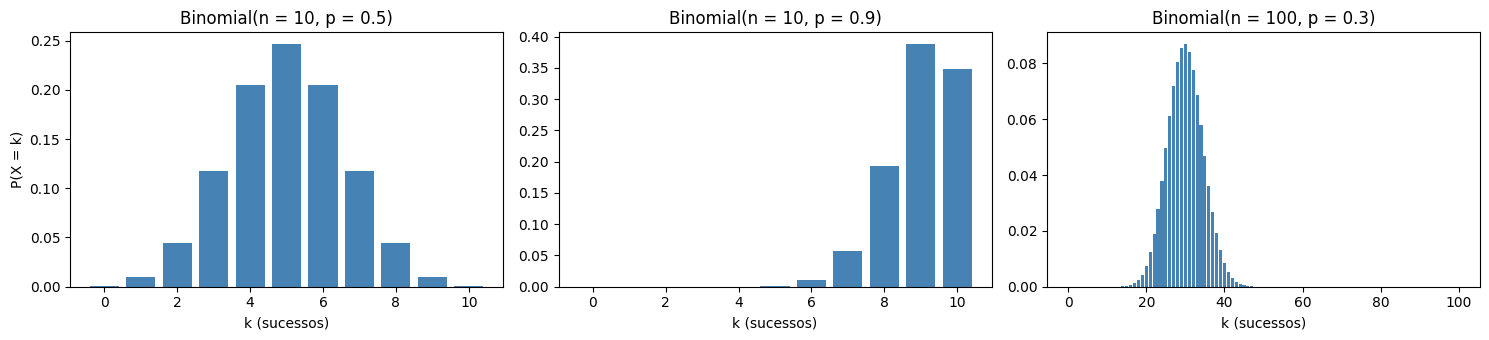

In [6]:
# O formato da binomial para diferentes n e p.
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (n_i, p_i) in zip(axes, [(10, 0.5), (10, 0.9), (100, 0.3)]):
    ks = np.arange(0, n_i + 1)
    ax.bar(ks, stats.binom.pmf(ks, n_i, p_i), color="steelblue")
    ax.set_title(f"Binomial(n = {n_i}, p = {p_i})")
    ax.set_xlabel("k (sucessos)")
axes[0].set_ylabel("P(X = k)")
plt.tight_layout()
plt.show()

**Conclusão:** a fórmula à mão e o scipy dão exatamente o mesmo resultado, e a simulação de 100.000 séries de 10 arremessos acompanha a PMF teórica até a terceira casa decimal. O valor mais provável é **7 acertos (26,7%)**, igual ao valor esperado $np = 7$, com variância $np(1-p) = 2{,}10$.

Mesmo para um bom arremessador, há **15,0%** de chance de acertar 5 ou menos (um "dia ruim") e só **2,8%** de chance de acertar todos os 10.

Nos gráficos: com $p = 0{,}5$ a binomial é **simétrica**; com $p = 0{,}9$ ela fica espremida contra o máximo e **assimétrica**; e com $n = 100$ ela volta a ter cara de **sino**, centrado em $np = 30$. Esse sino é a distribuição normal aparecendo, como veremos nos notebooks 08 e 10.

## 2. Uma aplicação: a acurácia num conjunto de teste pequeno

Um classificador tem acurácia **verdadeira** de 85% (ou seja, na população, acerta 85% dos casos). Nós o avaliamos num conjunto de teste com **100** exemplos. Se cada acerto é uma Bernoulli independente, o número de acertos é Binomial(100; 0,85). Que acurácias podemos **observar** no teste?

In [7]:
teste = stats.binom(100, 0.85)
# ppf é a inversa da cdf: o valor k tal que P(X ≤ k) = q. É o "quantil" da distribuição.
baixo, alto = teste.ppf(0.025), teste.ppf(0.975)
print(f"Acurácia esperada no teste: {teste.mean() / 100:.0%}")
print(f"Desvio padrão da acurácia observada: {teste.std() / 100:.1%}")
print(f"Em 95% das vezes, a acurácia observada fica entre {baixo / 100:.0%} e {alto / 100:.0%}")
print(f"P(observar 90% ou mais, só por sorte) = {teste.sf(89):.3f}")

Acurácia esperada no teste: 85%
Desvio padrão da acurácia observada: 3.6%
Em 95% das vezes, a acurácia observada fica entre 78% e 92%
P(observar 90% ou mais, só por sorte) = 0.099


**Conclusão:** mesmo com uma acurácia **verdadeira** de 85%, a acurácia medida num teste de 100 exemplos tem desvio padrão de **3,6 pontos percentuais**, e em 95% das vezes fica entre **78% e 92%**. Há quase **10%** de chance de o modelo marcar 90% ou mais só por sorte.

🔗 **Ponte para o ML:** uma diferença de 2 ou 3 pontos de acurácia entre dois modelos, num teste pequeno, pode ser puro acaso. É por isso que o ML-01 e o ML-02 usaram **validação cruzada** e olharam para a média **e o desvio padrão** das dobras. Os notebooks 11 e 12 vão transformar esta ideia em intervalos de confiança e testes.

## 🎓 Conceito: distribuição de Poisson

A **Poisson** conta **quantos eventos acontecem num intervalo** (de tempo ou de espaço) quando eles ocorrem de forma independente, a uma taxa média constante $\lambda$ ("lambda"):
- clientes que chegam a uma loja por hora;
- e-mails recebidos por dia;
- erros de digitação por página.

$$P(X = k) = \frac{\lambda^k e^{-\lambda}}{k!}, \qquad k = 0, 1, 2, \dots$$

Uma propriedade marcante: $E[X] = \text{Var}(X) = \lambda$. A média e a variância são **iguais**.

De onde ela vem? Divida uma hora em $n$ pedacinhos minúsculos; em cada um, a chance de chegar um cliente é $p = \lambda / n$. O total de chegadas é Binomial($n$, $\lambda/n$). Quando $n$ cresce muito (pedacinhos cada vez menores), essa binomial vira a Poisson. Por isso, a Poisson é uma boa aproximação para **eventos raros** com **muitas oportunidades**.

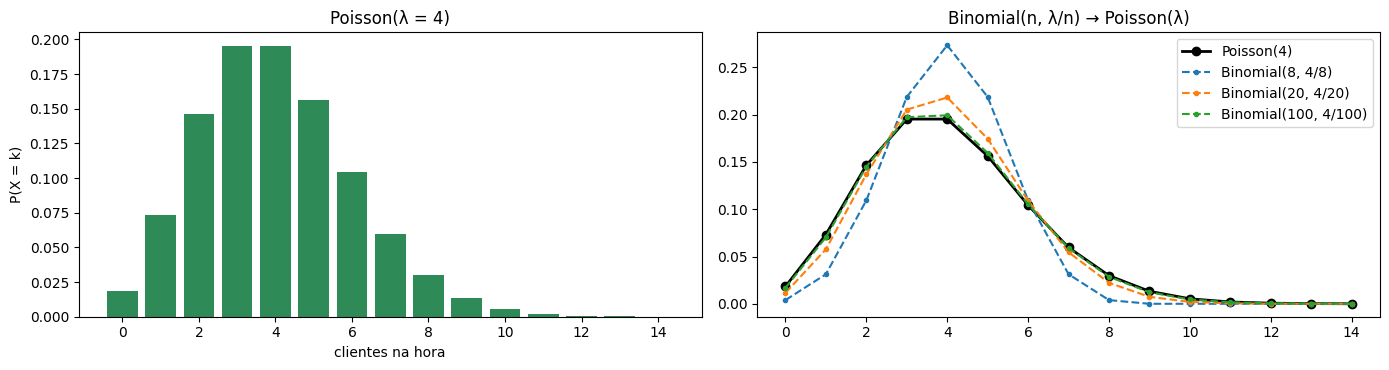

P(nenhum cliente numa hora)   = 0.0183
P(mais de 8 clientes)         = 0.0214
Simulação: média = 4.001, variância = 3.963   (as duas deveriam ser ≈ 4)


In [8]:
lam = 4   # uma loja recebe, em média, 4 clientes por hora
ks = np.arange(0, 15)
poisson = stats.poisson(lam)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].bar(ks, poisson.pmf(ks), color="seagreen")
axes[0].set_title(f"Poisson(λ = {lam})")
axes[0].set_xlabel("clientes na hora")
axes[0].set_ylabel("P(X = k)")

# A binomial com n grande e p = λ/n se aproximando da Poisson.
axes[1].plot(ks, poisson.pmf(ks), "ko-", label="Poisson(4)", linewidth=2)
for n_i in [8, 20, 100]:
    axes[1].plot(ks, stats.binom.pmf(ks, n_i, lam / n_i), marker=".", linestyle="--", label=f"Binomial({n_i}, 4/{n_i})")
axes[1].set_title("Binomial(n, λ/n) → Poisson(λ)")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"P(nenhum cliente numa hora)   = {poisson.pmf(0):.4f}")
print(f"P(mais de 8 clientes)         = {poisson.sf(8):.4f}")
amostra = rng.poisson(lam, size=100_000)
print(f"Simulação: média = {amostra.mean():.3f}, variância = {amostra.var():.3f}   (as duas deveriam ser ≈ {lam})")

**Conclusão:** com uma média de 4 clientes por hora, há **1,8%** de chance de uma hora sem nenhum cliente e **2,1%** de chance de mais de 8 clientes. A PMF é levemente assimétrica à direita (pode haver 10 ou 12 clientes, mas nunca menos de zero), com os valores 3 e 4 empatados como mais prováveis.

O gráfico da direita mostra a binomial se aproximando da Poisson: com $n = 8$ (azul) ela é bem mais "estreita", com $n = 20$ (laranja) já fica perto, e com $n = 100$ (verde) as curvas praticamente se sobrepõem. Na simulação, a média (**4,001**) e a variância (**3,963**) ficam ambas perto de 4, a assinatura da Poisson.

Na prática, quando dados de contagem têm variância **muito maior** que a média, isso é sinal de que a Poisson não serve (os eventos não são independentes ou a taxa varia), um fenômeno chamado **superdispersão**.

## 🎓 Conceito: distribuição geométrica

A **geométrica** conta **quantas tentativas** são necessárias até o **primeiro sucesso**, com probabilidade $p$ de sucesso em cada tentativa independente:

$$P(X = k) = (1-p)^{k-1}\, p, \qquad k = 1, 2, 3, \dots$$

($k - 1$ fracassos seguidos de um sucesso.) O valor esperado é $E[X] = 1/p$: se a chance é de 1 em 6, esperamos, em média, 6 tentativas.

Ela tem uma propriedade curiosa, a **falta de memória**: se você já falhou 10 vezes, a chance de precisar de mais $k$ tentativas é a mesma de quem está começando agora. O dado não "lembra" do passado, por isso a ideia de que "um 6 está para sair" é uma falácia (a **falácia do apostador**).

In [9]:
p6 = 1 / 6   # chance de tirar 6 num dado
geometrica = stats.geom(p6)

# Simulação "à mão": para cada jogador, contar quantos lançamentos até sair o primeiro 6.
def lancar_ate_6():
    tentativas = 1
    while rng.integers(1, 7) != 6:   # while: repete enquanto a condição for verdadeira
        tentativas += 1
    return tentativas

amostra_geo = np.array([lancar_ate_6() for _ in range(20_000)])   # "_" é o nome usual para uma variável que não usamos

print(f"E[X] = 1/p = {1 / p6:.2f}   simulação: {amostra_geo.mean():.2f}")
print(f"P(sair o 6 já na 1ª tentativa)  = {geometrica.pmf(1):.4f}")
print(f"P(precisar de mais de 10)        = {geometrica.sf(10):.4f}   simulação: {np.mean(amostra_geo > 10):.4f}")

# Falta de memória: entre quem já falhou 10 vezes, qual a chance de precisar de mais de 10 tentativas ADICIONAIS?
ja_falhou = amostra_geo[amostra_geo > 10]
print(f"P(mais 10 | já falhou 10)        ≈ {np.mean(ja_falhou > 20):.4f}   (igual a começar do zero!)")

E[X] = 1/p = 6.00   simulação: 6.06
P(sair o 6 já na 1ª tentativa)  = 0.1667
P(precisar de mais de 10)        = 0.1615   simulação: 0.1651
P(mais 10 | já falhou 10)        ≈ 0.1683   (igual a começar do zero!)


**Conclusão:** em média são necessários **6** lançamentos para tirar o primeiro 6 (a simulação deu **6,06**), mas a distribuição é bem espalhada: há **16,2%** de chance de precisar de **mais de 10** lançamentos (simulação: 16,5%).

A falta de memória aparece claramente: entre os jogadores que já tinham falhado 10 vezes, a proporção que precisou de mais 10 tentativas foi **16,8%**, praticamente a mesma chance (16,2%) de quem começa do zero. As 10 falhas anteriores não deixam o próximo 6 "mais perto".

## 3. Resumo e próximos passos

| Distribuição | Conta... | Parâmetros | $E[X]$ | $\text{Var}(X)$ | `scipy.stats` |
|---|---|---|---|---|---|
| Bernoulli | sucesso (1) ou fracasso (0) | $p$ | $p$ | $p(1-p)$ | `bernoulli(p)` |
| Binomial | sucessos em $n$ tentativas | $n, p$ | $np$ | $np(1-p)$ | `binom(n, p)` |
| Poisson | eventos num intervalo | $\lambda$ | $\lambda$ | $\lambda$ | `poisson(lam)` |
| Geométrica | tentativas até o 1º sucesso | $p$ | $1/p$ | $(1-p)/p^2$ | `geom(p)` |

Os métodos das distribuições do `scipy.stats`: `.pmf(k)` = $P(X = k)$; `.cdf(k)` = $P(X \le k)$; `.sf(k)` = $P(X > k)$; `.ppf(q)` = quantil; `.mean()`, `.var()`, `.std()`; `.rvs(size=...)` = sorteia valores.

**Conceitos que você aprendeu**
- **Variável aleatória** e **PMF**.
- **Valor esperado** e **variância**, a linearidade da esperança e a variância da soma de independentes.
- As distribuições **Bernoulli, binomial, Poisson e geométrica**, de onde vêm suas fórmulas e quando usar cada uma.
- A incerteza da **acurácia** medida num conjunto de teste pequeno.
- A **falta de memória** da geométrica e a falácia do apostador.

🔗 **Ponte para o ML:** a Bernoulli é o alvo da classificação binária; a binomial descreve a incerteza de métricas como a acurácia; a Poisson é a base da **regressão de Poisson**, usada para prever contagens.

**Python novo:** list comprehension com dois `for`, `np.full`, `stats.binom` / `poisson` / `geom` e os métodos `.pmf`, `.cdf`, `.sf`, `.ppf`, `np.allclose`, `rng.binomial` / `poisson`, `while`, `_` como variável descartável.

**Próximo notebook:** e quando a variável pode assumir **qualquer** valor num intervalo, como a altura, o peso ou o valor de uma conta? No notebook 08 vamos às **variáveis contínuas**: a **função densidade**, a distribuição **normal** (a famosa curva em sino), o **z-score** e o **Q-Q plot**.